# MATH 60231 – Homework #3
**Group:** Mathis Huot, Nathan Madore, Isabelle Tanara

Due: Monday, November 23, 2026

# Setup

In [15]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import statsmodels.api as sm
from statsmodels.tsa.ar_model import AutoReg
from statsmodels.tsa.stattools import adfuller
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf
from numpy.random import default_rng, PCG64
from scipy import stats

## Table formatting functions

Tables are drawn in the style of finance research papers (horizontal rules only, serif font, optional panels and notes). The functions are reused from our own Case Study 1 notebook. The underlying matplotlib table/text drawing follows [MatPlotLib - Table Demo](https://matplotlib.org/stable/gallery/misc/table_demo.html).

In [16]:
# Table formatting (reused from our Case Study 1 notebook, adapted to one Output/ folder)
import os, re, textwrap
from IPython.display import display
os.makedirs("Output", exist_ok=True)                       # every table and figure is also saved as a PNG in Output/


def save_output(fig, label):
    """Save a matplotlib figure as a PNG (200 dpi) in the Output/ folder.

    Parameters
    ----------
    fig : matplotlib.figure.Figure
        Figure to save.
    label : str
        Table/figure title; turned into a safe file name
        (e.g. "Table 2.1 - Descriptive statistics" -> "Output/Table_2.1_Descriptive_statistics.png").
    """
    name = re.sub(r"[^A-Za-z0-9.]+", "_", label).strip("_.")[:90]
    fig.savefig(f"Output/{name}.png", dpi=200, bbox_inches="tight")


# ---------- Number formats used in the tables ----------
#   "num"  -> 2 decimals            "num3" -> 3 decimals (e.g. autocorrelations)
#   "num4" -> 4 decimals            "pval" -> 3 decimals (p-values)
#   "pct"  -> 0.0013 shown as 0.13% "int"  -> 397

def format_value(x, kind="num"):
    """Format one number as text for a table.

    Parameters
    ----------
    x : float or str
        Value to format (NaN is shown as a dash, text such as a date is shown as is).
    kind : str
        "num" (2 decimals), "num3" (3 decimals), "num4" (4 decimals), "pval" (3 decimals),
        "pct" (percentage, 2 decimals) or "int" (whole number).

    Returns
    -------
    str
        Formatted value, e.g. 0.0013 with kind="pct" -> "0.13%".
    """
    if isinstance(x, str):
        return x
    if pd.isna(x):
        return "–"
    if kind == "pct":
        return f"{x * 100:.2f}%"
    if kind == "int":
        return f"{x:,.0f}"
    if kind in ("pval", "num3"):
        return f"{x:,.3f}"
    if kind == "num4":
        return f"{x:,.4f}"
    return f"{x:,.2f}"


def format_table(df, row_formats=None, col_formats=None, default="num"):
    """Return a copy of a table with every number formatted as text.

    The format of a cell is taken from its column (col_formats) if listed, otherwise from
    its row (row_formats), otherwise `default`.

    Parameters
    ----------
    df : pd.DataFrame
        Table of numbers.
    row_formats : dict, optional
        Maps a row label to a format kind (see format_value).
    col_formats : dict, optional
        Maps a column label to a format kind (useful when rows are series and columns are statistics).
    default : str
        Format kind used when neither the row nor the column is listed.

    Returns
    -------
    pd.DataFrame
        Same shape as df, with formatted strings.
    """
    row_formats, col_formats = row_formats or {}, col_formats or {}
    out = df.astype(object).copy()
    for r in df.index:
        for c in df.columns:
            kind = col_formats.get(c, row_formats.get(r, default))
            out.loc[r, c] = format_value(df.loc[r, c], kind)
    return out


def split_title(title):
    """Split "Table 2.1 - Description" (hyphen or en dash) into ("Table 2.1", "Description")."""
    number, _, description = re.sub(r"\s+[–-]\s+", " - ", title, count=1).partition(" - ")
    return number, description


# ---------- Table image in the style of finance research papers ----------
def save_table_png(panels, title, notes=None, row_formats=None, col_formats=None, default="num",
                   width=7.5, label_width=3.3):
    """Draw a table as an image in the style of finance research papers and save it to Output/.

    Horizontal rules only (thick top and bottom, thin under the header and between panels),
    italic panel labels, serif font, and an optional notes paragraph under the table.

    Parameters
    ----------
    panels : dict
        {panel label: DataFrame}; all panels must have the same columns ("" = no panel label).
    title : str
        "Table X.Y - Description" (number in bold, description below).
    notes : str, optional
        Notes printed under the table.
    row_formats, col_formats, default
        Number formats (see format_table).
    width : float
        Width of the image in inches.
    label_width : float
        Width of the row-label column in inches.
    """
    columns = list(next(iter(panels.values())).columns)

    # List of lines to draw, top to bottom
    lines = []
    for panel_name, df in panels.items():
        if panel_name:
            lines.append(("panel", panel_name))
        for label, row in format_table(df, row_formats, col_formats, default).iterrows():
            lines.append(("row", label, list(row)))

    # Sizes in inches (the drawing uses inches as coordinates, measured from the top)
    margin, row_h = 0.3, 0.26
    title_h = 0.65
    notes_text = textwrap.fill(notes, int(150 * width / 7.5)) if notes else ""
    notes_h = 0.16 * (notes_text.count("\n") + 1) + 0.2 if notes else 0.1
    table_h = row_h * (len(lines) + 1.6) + 0.12 * (len(panels) - 1)
    height = title_h + table_h + notes_h

    left, right = margin, width - margin
    first_value_x = margin + label_width                 # values start to the right of the row labels
    col_w = (right - first_value_x) / len(columns)
    col_x = [first_value_x + (i + 0.5) * col_w for i in range(len(columns))]

    with plt.rc_context({"font.family": "serif", "font.serif": ["Times New Roman", "Times", "DejaVu Serif"]}):
        fig = plt.figure(figsize=(width, height))
        ax = fig.add_axes([0, 0, 1, 1])
        ax.set_xlim(0, width)
        ax.set_ylim(height, 0)                           # y grows downward
        ax.axis("off")

        number, description = split_title(title)
        ax.text(width / 2, 0.2, number, ha="center", va="center", fontsize=11, fontweight="bold")
        ax.text(width / 2, 0.45, description, ha="center", va="center", fontsize=11)

        y = title_h
        ax.hlines(y, left, right, color="black", linewidth=1.3)              # top rule
        y += row_h * 0.6
        for x, col in zip(col_x, columns):
            ax.text(x, y, col, ha="center", va="center", fontsize=10)
        y += row_h * 0.55
        ax.hlines(y, left, right, color="black", linewidth=0.6)              # rule under the header
        y += row_h * 0.55

        first_panel = True
        for line in lines:
            if line[0] == "panel":
                if not first_panel:                                          # thin rule between panels
                    y += 0.06
                    ax.hlines(y - row_h * 0.5, left, right, color="black", linewidth=0.4)
                    y += 0.06
                ax.text(left, y, line[1], ha="left", va="center", fontsize=10, style="italic")
                first_panel = False
            else:
                _, label, values = line
                ax.text(left + 0.15, y, label, ha="left", va="center", fontsize=10)
                for x, value in zip(col_x, values):
                    ax.text(x, y, value, ha="center", va="center", fontsize=10)
            y += row_h

        y -= row_h * 0.45
        ax.hlines(y, left, right, color="black", linewidth=1.3)              # bottom rule

        if notes:
            ax.text(left, y + 0.12, notes_text, ha="left", va="top", fontsize=8, linespacing=1.4)

        save_output(fig, title)
        plt.close(fig)   # saved only; the formatted table is displayed in the notebook instead


def save_table(table, title, notes=None, row_formats=None, col_formats=None, default="num", **layout):
    """Save a table as a finance-paper-style PNG in Output/ and display it formatted in the notebook.

    Parameters
    ----------
    table : pd.DataFrame or dict
        One table, or {"Panel A: ...": df_a, "Panel B: ...": df_b} for a multi-panel table.
    title : str
        "Table X.Y - Description"; also used for the file name.
    notes : str, optional
        Notes printed under the table.
    row_formats, col_formats, default
        Number formats (see format_table).
    **layout
        Optional width and label_width of the image (see save_table_png).
    """
    panels = table if isinstance(table, dict) else {"": table}
    save_table_png(panels, title, notes, row_formats, col_formats, default, **layout)

    print(title)
    for panel_name, df in panels.items():
        if panel_name:
            print(panel_name)
        display(format_table(df, row_formats, col_formats, default))

## Data loading

In [17]:
# Problem 1: hourly PJM, Zonal COMED price only
PJM_data = pd.read_csv('Data/PJM.csv', skipinitialspace=True, parse_dates=['Date'], index_col='Date')
PJM_data.columns = ["price", "S_load", "Z_load"]
price_h = PJM_data['price'].iloc[-8760:]               # last 8,760 hours = calendar year 2018
price_d = PJM_data['price'].resample('D').mean()       # daily average, as in HW2 (only used in 1e)

# Problem 2 (a)-(e): daily UK gilt yields, 15 maturities
gilts = pd.read_parquet('Data/UK_bonds.parquet')

# Problem 2 (d), (f): S&P 500, oldest first, in logs
spx = pd.read_csv('Data/S&P 500 Historical Data.csv', thousands=',',
                  parse_dates=['Date'], index_col='Date').sort_index()
log_spx = np.log(spx['Price'])

print(price_h.index[[0, -1]], gilts.shape, log_spx.index[[0, -1]])

DatetimeIndex(['2017-12-25 00:00:00', '2018-12-24 23:00:00'],
              dtype='datetime64[us]', name='Date', freq=None) (1114, 15) DatetimeIndex(['2002-01-02', '2021-11-09'], dtype='datetime64[us]', name='Date',
              freq=None)


# Problem 1 – Simulating Forecast Uncertainty [40 pts]
Hourly PJM data, `price` (Zonal COMED) only, last 8,760 hourly observations (2018). Do **not** aggregate to daily (except in 1e).

## 1a. `Q1_ARForecast()` [5 pts]
Function taking a p×1 array `s` (most recent p obs) and a (1+p)×1 array `phi`; returns the 1-step-ahead forecast ŝ(t+1) = φ0 + Σ φj·s(t−j+1). Apply with an AR(24) estimated on 2018 hourly prices.

In [18]:
def Q1_ARForecast(s, phi):
    s = np.array(s, dtype=float).ravel()  # ensure s is a 1D array
    phi = np.asarray(phi, dtype=float).ravel()
    p = len(phi)-1 # AR order is one less than the length of phi

    # Safety check (SIZE OF INPUTS)
    if len(s) != p:                                    
        raise ValueError(f"s has {len(s)} observations but phi implies p = {p}")

    # Forecast formula
    return float(phi[0] + phi[1:] @ s[::-1])


# Estimating AR(24)
p = 24
phi_24 = AutoReg(price_h.values, lags=p).fit().params

# 1-step-ahead forecast from the last 24 hours of 2018
fc_1a = Q1_ARForecast(price_h.values[-p:], phi_24)
target = price_h.index[-1] + pd.Timedelta(hours=1)

# Values to compare the forecast with, in the write-up
table_1a = pd.DataFrame({
    'AR(24) forecast': [fc_1a],
    'Last observed price (t)': [price_h.iloc[-1]],
    'Same hour, previous day (t-23)': [price_h.iloc[-24]],
    '2018 mean price': [price_h.mean()],
}, index=[str(target)])

notes_1a = (f"Notes: AR(24) estimated by OLS on the last 8,760 hourly Zonal COMED prices "
            f"({price_h.index[0]:%B %-d, %Y} to {price_h.index[-1]:%B %-d, %Y}). The forecast is for the hour "
            f"after the last observation ({target:%Y-%m-%d %H:%M}), using the 24 most recent prices. "
            "All values in $/MWh.")
save_table(table_1a, "Table 1.1 - AR(24) one-step-ahead forecast of the hourly COMED price ($/MWh)",
           notes=notes_1a, width=10, label_width=1.7)


Table 1.1 - AR(24) one-step-ahead forecast of the hourly COMED price ($/MWh)


,AR(24) forecast,Last observed price (t),"Same hour, previous day (t-23)",2018 mean price
2018-12-25 00:00:00,22.98,23.98,21.00,28.94


## 1b. `Q1_AREstimate()` [10 pts]
Function taking a T×1 array `s` and integer `p`; returns the (1+p)×1 coefficients `phi` and the (T−p)×1 in-sample residuals. Apply with p = 24; report coefficients and plot the residual ACF.


Max |our phi - statsmodels phi| = 1.0769163338864018e-14
Table 1.2 - AR(24) coefficients, 2018 hourly COMED price


,Coefficient,Std. error,p-value
Constant,0.617,0.139,0.000
Lag 1,1.147,0.011,0.000
Lag 2,-0.362,0.016,0.000
Lag 3,0.048,0.016,0.003
Lag 4,0.018,0.016,0.266
Lag 5,-0.051,0.016,0.002
Lag 6,0.018,0.016,0.277
Lag 7,-0.014,0.016,0.400
Lag 8,-0.008,0.016,0.617
Lag 9,-0.000,0.016,0.986


Table 1.3 - Largest AR(24) lag coefficients in absolute value


,Coefficient,Std. error,p-value
Lag 1,1.147,0.011,0.000
Lag 2,-0.362,0.016,0.000
Lag 23,0.305,0.016,0.000
Lag 24,-0.131,0.011,0.000
Lag 10,0.054,0.016,0.001
Lag 5,-0.051,0.016,0.002


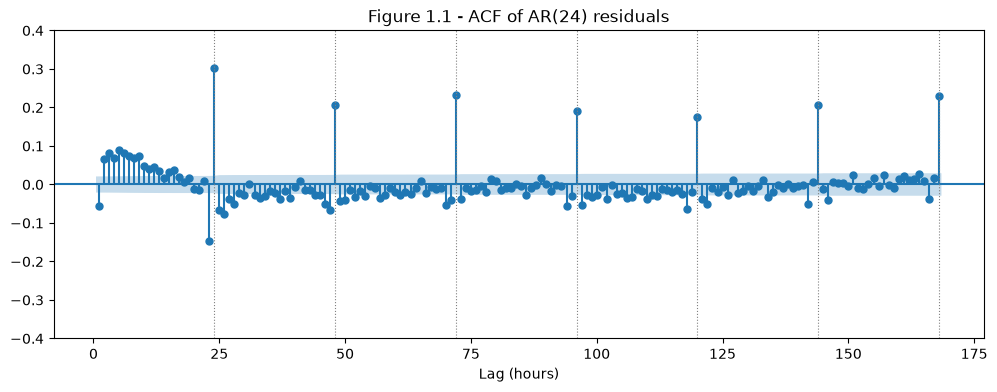

In [19]:
def Q1_AREstimate(s, p):
    """Estimate an AR(p) model by OLS.

    Regresses s_t on a constant and its p lags: s_t = phi_0 + sum_j phi_j * s_{t-j} + e_t.

    Parameters
    ----------
    s : array-like, shape (T,)
        The series [s_1, ..., s_T], oldest to newest.
    p : int
        AR order (number of lags).

    Returns
    -------
    phi : np.ndarray, shape (1 + p,)
        Estimated coefficients [phi_0, phi_1, ..., phi_p].
    resid : np.ndarray, shape (T - p,)
        In-sample residuals e_hat_t = s_t - s_hat_t, for t = p+1, ..., T.
    """
    s = np.asarray(s, dtype=float).ravel()  
    T = len(s)
    y = s[p:]                                          # target value being explained

    # Regressor matrix
    X = np.column_stack([np.ones(T - p)] + [s[p - j:T - j] for j in range(1, p + 1)])
    phi = np.linalg.lstsq(X, y, rcond=None)[0]         # phi (OLS) = (X'X)^-1 X'y 
    resid = y - X @ phi                                # Residuals

    return phi, resid


# Apply to hourly price with lags = 24
p = 24
phi_24, resid_24 = Q1_AREstimate(price_h.values, p)

# Gives standard errors and p-values for the table (and cross-validates with statsmodels)
ar_24 = AutoReg(price_h.values, lags=p).fit()
print("Max |our phi - statsmodels phi| =", np.abs(phi_24 - ar_24.params).max())

# (i) Coefficient table
coef_1b = pd.DataFrame({'Coefficient': phi_24,
                        'Std. error': ar_24.bse,
                        'p-value': ar_24.pvalues},
                       index=['Constant'] + [f'Lag {j}' for j in range(1, p + 1)])

# Calling table formatting
notes_1b = ("Notes: AR(24) estimated by OLS with Q1_AREstimate() on the last 8,760 hourly Zonal COMED prices "
            "($/MWh). Standard errors and p-values are the conventional OLS ones from statsmodels AutoReg "
            "(same coefficients as Q1_AREstimate()).")
save_table(coef_1b, "Table 1.2 - AR(24) coefficients, 2018 hourly COMED price", notes=notes_1b,
           col_formats={"p-value": "pval"}, default="num3", width=6, label_width=1.3)

# (i) Lags ranked by absolute size  
lags_1b = coef_1b.iloc[1:]
top_1b = lags_1b.loc[lags_1b['Coefficient'].abs().sort_values(ascending=False).index].head(6)

# Calling table formatting
save_table(top_1b, "Table 1.3 - Largest AR(24) lag coefficients in absolute value",
           notes="Notes: The six lag coefficients of Table 1.2 with the largest absolute value, largest first.",
           col_formats={"p-value": "pval"}, default="num3", width=6, label_width=1.3)

# (ii) Build figure for ACF of the residuals over 168 hours
fig, ax = plt.subplots(figsize=(12, 4))
plot_acf(resid_24, lags=168, ax=ax, zero=False)
for k in range(24, 169, 24):                           # Lines at multiples of 24 h
    ax.axvline(k, color='grey', ls=':', lw=0.8)
ax.set_xlabel('Lag (hours)')
ax.set_ylim(-0.4, 0.4)
ax.set_title('Figure 1.1 - ACF of AR(24) residuals')
save_output(fig, "Figure 1.1 - ACF of AR(24) residuals")
plt.show()


## 1c. `Q1_SimPath()` [10 pts]
Function taking a BitGenerator `bg`, `s` (last p obs), `phi`, residuals `e` and horizon `h`; returns one simulated path of length h (AR recursion + bootstrapped residuals). Apply with h = 48; plot 3 paths with the last 72 in-sample hours and a vertical separator.

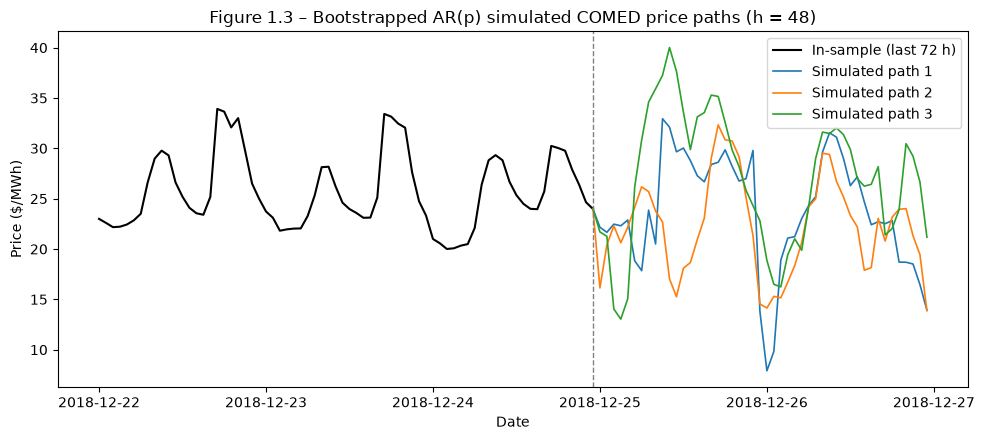

In [20]:
def Q1_SimPath(bg, s, phi, e, h):
    rng = np.random.Generator(bg)                               
    s, phi, e = (np.asarray(x, dtype=float).ravel() for x in (s, phi, e))   # accept p x 1 / (1+p) x 1 / T x 1 arrays
    lags = s[::-1].copy()                                                   # s is oldest -> newest; flip so lags = [s_t, s_{t-1}, ..., s_{t-p+1}]
    path = np.empty(h)
    for i in range(h):
        eps = e[rng.integers(len(e))]                           # bootstrap: one residual drawn uniformly at random from e
        path[i] = phi[0] + phi[1:] @ lags + eps                 # AR(p) recursion: phi_0 + phi_1 s_t + ... + phi_p s_{t-p+1} + eps
        lags = np.r_[path[i], lags[:-1]]                        # new value becomes lag 1, oldest lag drops out
    return path                                                 # [s_{t+1}, ..., s_{t+h}]

# Applying the function with h = 48 on hourly 2018 COMED price
p = 24                                                          # Lag order selected earlier in Problem 1
res = AutoReg(price_h.values, lags=p).fit()                     

phi = res.params                                                # (1+p): [const, L1, ..., Lp]
e = res.resid                                                   # in-sample residuals to bootstrap from
s = price_h.values[-p:]                                         # p most recent hours (oldest -> newest)
bg = np.random.PCG64(42)                                        
h = 48

paths = [Q1_SimPath(bg, s, phi, e, h) for _ in range(3)]

# Figure 1.1: last 72 hours of data + 3 simulated paths
last = price_h.index[-1]
future = pd.date_range(last + pd.Timedelta(hours=1), periods=h, freq='h')

fig, ax = plt.subplots(figsize=(10, 4.5))
ax.plot(price_h.index[-72:], price_h.iloc[-72:], color='black', lw=1.5, label='In-sample (last 72 h)')
for k, path in enumerate(paths, 1):
    ax.plot(np.r_[last, future], np.r_[price_h.iloc[-1], path], lw=1.2, label=f'Simulated path {k}')  # start each path at the last observation so it joins the data
ax.axvline(last, color='grey', ls='--', lw=1)                   # separates in-sample from simulated
ax.set_title('Figure 1.3 – Bootstrapped AR(p) simulated COMED price paths (h = 48)')
ax.set_xlabel('Date')
ax.set_ylabel('Price ($/MWh)')
ax.legend()
fig.tight_layout()
plt.savefig('Q1_SimPath.png', dpi=200, bbox_inches='tight')
plt.show()

## 1d. `Q1_SimBands()` [10 pts]
Function taking `bg`, `s`, and integers `p`, `h`, `N`; returns an N×h array of paths by calling `Q1_SimPath()` N times (same `phi` and residuals). Apply with p = 24, h = 48, N = 1,000; plot 5th/95th percentiles with the point forecast.

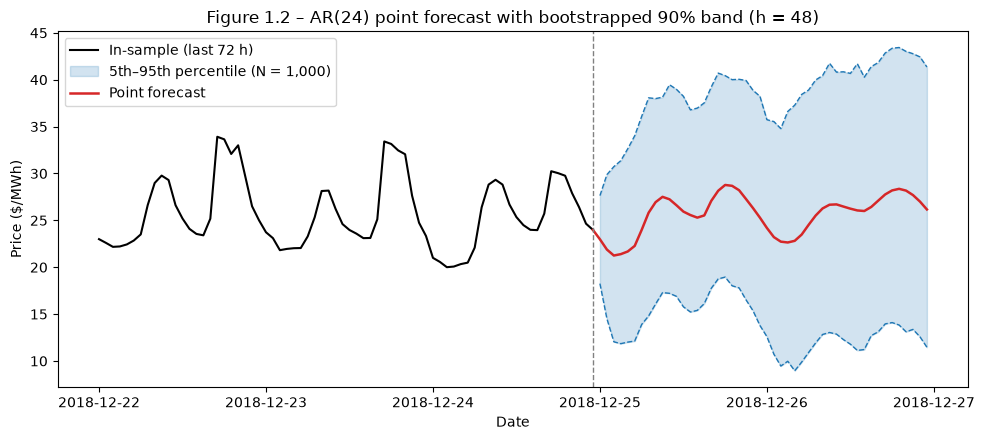

In [21]:
def Q1_SimBands(bg, s, p, h, N):
    s = np.asarray(s, dtype=float).ravel()                      # accept a T x 1 array
    phi, e = Q1_AREstimate(s, p)                                # estimate once; every path reuses the same phi and residuals
    s_last = s[-p:]                                             # p most recent observations (oldest -> newest)
    return np.vstack([Q1_SimPath(bg, s_last, phi, e, h)        
                      for _ in range(N)])                       # N x h array

# Applying the function with p = 24, h = 48, N = 1,000 on the 2018 hourly price
p, h, N = 24, 48, 1000
bg = np.random.PCG64(42)                                        
sims = Q1_SimBands(bg, price_h.values, p, h, N)                 # (1000, 48)

# Point forecast: same AR(p) recursion with every shock set to zero
phi, e = Q1_AREstimate(price_h.values, p)
point = Q1_SimPath(np.random.PCG64(), price_h.values[-p:], phi, np.zeros(1), h)   

q05, q95 = np.percentile(sims, [5, 95], axis=0)                

# Figure 1.2: 90% simulated band and point forecast
last = price_h.index[-1]
future = pd.date_range(last + pd.Timedelta(hours=1), periods=h, freq='h')

fig, ax = plt.subplots(figsize=(10, 4.5))
ax.plot(price_h.index[-72:], price_h.iloc[-72:], color='black', lw=1.5, label='In-sample (last 72 h)')
ax.fill_between(future, q05, q95, color='tab:blue', alpha=0.2, label='5th–95th percentile (N = 1,000)')
ax.plot(future, q05, color='tab:blue', lw=1, ls='--')
ax.plot(future, q95, color='tab:blue', lw=1, ls='--')
ax.plot(np.r_[last, future], np.r_[price_h.iloc[-1], point], color='tab:red', lw=1.8, label='Point forecast')
ax.axvline(last, color='grey', ls='--', lw=1)                   # separates in-sample from forecast
ax.set_title('Figure 1.2 – AR(24) point forecast with bootstrapped 90% band (h = 48)')
ax.set_xlabel('Date')
ax.set_ylabel('Price ($/MWh)')
ax.legend(loc='upper left')
fig.tight_layout()
plt.savefig('Q1_SimBands.png', dpi=200, bbox_inches='tight')
plt.show()

## 1e. DM test: hourly AR(24) vs daily AR(6) [5 pts]
Average the hourly AR(24) 1-step-ahead rolling forecasts within each day, then compare with the HW2 daily AR(6) forecasts using `Q2_DM()`. Report the DM statistic and p-value.

### HW2 carry-over (same as Homework 2)
Functions and daily AR(6) forecasts copied unchanged from Homework 2, Problem 2 (d)–(e).

In [22]:
# ---- Carried over from Homework 2 (unchanged): Q2_RollForecast, Q2_Realised, Q2_DM ----
def Q2_RollForecast(s, T0, p, h):
    """Rolling fixed-window AR(p) forecasts.

    For each window of T0 consecutive observations, re-estimate AR(p) on that
    window only and forecast the next h days. The window then moves forward
    by one day.

    Parameters
    ----------
    s : array-like
        The series (daily COMED price).
    T0 : int
        Window length (number of observations used in each estimation).
    p : int
        AR order.
    h : int
        Maximum forecast horizon.

    Returns
    -------
    np.ndarray
        Shape (n_windows, h): row i = forecasts for h = 1..h from window i.
    """
    s = np.asarray(s, dtype=float)
    n_windows = len(s) - T0 - h + 1                  # last window still has h realised values after it
    forecasts = np.empty((n_windows, h))
    
    # Loop over all windows, re-estimate AR(p) on each window, and forecast h steps ahead
    for i in range(n_windows):
        window = s[i:i + T0]                         
        res = AutoReg(window, lags=p).fit()          # re-estimate AR(p) on this window only
        forecasts[i] = res.forecast(h)               
    
    return forecasts


def Q2_Realised(s, T0, h):
    """Actual values matching the forecasts of Q2_RollForecast().

    Parameters
    ----------
    s : array-like
        The series (daily COMED price).
    T0 : int
        Window length (same as in Q2_RollForecast()).
    h : int
        Maximum forecast horizon.

    Returns
    -------
    np.ndarray
        Shape (n_windows, h): row i = the h values observed right after window i.
        Forecast errors are then realised - forecasts.
    """
    s = np.asarray(s, dtype=float)
    n_windows = len(s) - T0 - h + 1
    realised = []
    
    for i in range(n_windows):                       # the h values right after window i
        realised.append(s[i + T0:i + T0 + h])
    
    return np.array(realised)


def Q2_DM(d, h):
    """Diebold-Mariano statistic for H0: E[d] = 0.

    The statistic is mean(d) divided by its standard error. The variance uses
    a Newey-West (Bartlett-weighted) long-run variance with h - 1
    autocovariances, because h-step forecast errors overlap.

    Parameters
    ----------
    d : array-like
        Loss differential, one value per forecast.
        Equal MSFE (2e): d = e_AR3^2 - e_AR6^2.
        Encompassing (2f): d = e_AR3 * (e_AR3 - e_AR6).
    h : int
        Forecast horizon.

    Returns
    -------
    float
        DM statistic, approximately N(0, 1) under H0.
    """
    d = np.asarray(d, dtype=float)
    T = len(d)
    u = d - d.mean()
    lrv = u @ u / T                                      
    
    for k in range(1, h):                                # h-1 autocovariances (MA(h-1) under H0)
        lrv += 2 * (1 - k / h) * (u[k:] @ u[:-k]) / T    # Bartlett weighted variance (keeps it positive)
    
    return d.mean() / np.sqrt(lrv / T)                   # ~ N(0,1) under H0: E[d] = 0


# HW2 daily AR(6) rolling forecasts (same settings as HW2: T0 = 300, h = 24)
T0, h = 300, 24
forecast_ar6 = Q2_RollForecast(price_d, T0, 6, h)

# 1-step-ahead AR(6) daily forecasts, indexed by the day being forecast
ar6_1step = pd.Series(forecast_ar6[:, 0], index=price_d.index[T0:T0 + len(forecast_ar6)])
print(ar6_1step.tail())

Date
2018-11-27    31.361982
2018-11-28    34.304263
2018-11-29    37.460548
2018-11-30    33.055005
2018-12-01    33.439457
Freq: D, dtype: float64


# Problem 2 – Unit Roots & Cointegration [50 pts]
Parts (a)–(e): `UK_bonds.parquet` (daily gilt yields, 15 maturities). Parts (d), (f): `S&P 500 Historical Data.csv` (log index).

## 2a. Descriptive statistics & graphs [5 pts]
Descriptive statistics for all maturities; one labelled time-series plot (2Yr, 5Yr, 10Yr, 40Yr); mean yield curve across maturities.

Table 2.1 - Descriptive statistics of daily UK gilt yields


,Mean,Std,Min,Median,Max,Skew,Ex. kurt,AC(1) level,Std Δy,AC(1) Δy,% days < 0
9M,0.61,0.74,-0.15,0.58,4.06,2.11,5.28,0.998,0.043,0.141,16.79
10M,0.62,0.75,-0.15,0.58,4.14,2.13,5.35,0.998,0.044,0.143,17.41
11M,0.62,0.76,-0.15,0.58,4.21,2.14,5.40,0.998,0.046,0.145,17.77
1Yr,0.63,0.77,-0.15,0.57,4.26,2.15,5.45,0.998,0.047,0.147,18.31
2Yr,0.65,0.81,-0.14,0.51,4.53,2.23,5.91,0.998,0.053,0.161,16.70
3Yr,0.68,0.81,-0.16,0.51,4.57,2.24,6.18,0.998,0.054,0.158,15.53
5Yr,0.75,0.80,-0.13,0.55,4.54,2.15,6.00,0.998,0.054,0.122,12.21
7Yr,0.87,0.78,-0.06,0.64,4.51,1.99,5.33,0.998,0.055,0.078,1.62
10Yr,1.06,0.77,0.11,0.88,4.54,1.79,4.40,0.997,0.055,0.034,0.00
13Yr,1.25,0.76,0.28,1.08,4.72,1.74,4.11,0.997,0.057,0.020,0.00


Table 2.2 - Negative-yield episode by maturity


,First day < 0,Last day < 0,Days < 0,Min yield (%),Date of min
9M,2020-06-29,2021-05-25,187,-0.153,2020-12-31
10M,2020-06-29,2021-05-25,194,-0.152,2020-12-31
11M,2020-06-24,2021-05-26,198,-0.151,2020-12-31
1Yr,2020-06-22,2021-05-26,204,-0.150,2020-12-31
2Yr,2020-05-21,2021-02-23,186,-0.142,2020-09-08
3Yr,2020-05-21,2021-02-03,173,-0.163,2020-09-08
5Yr,2020-05-21,2021-01-28,136,-0.134,2020-07-30
7Yr,2020-07-10,2020-09-21,18,-0.060,2020-08-04


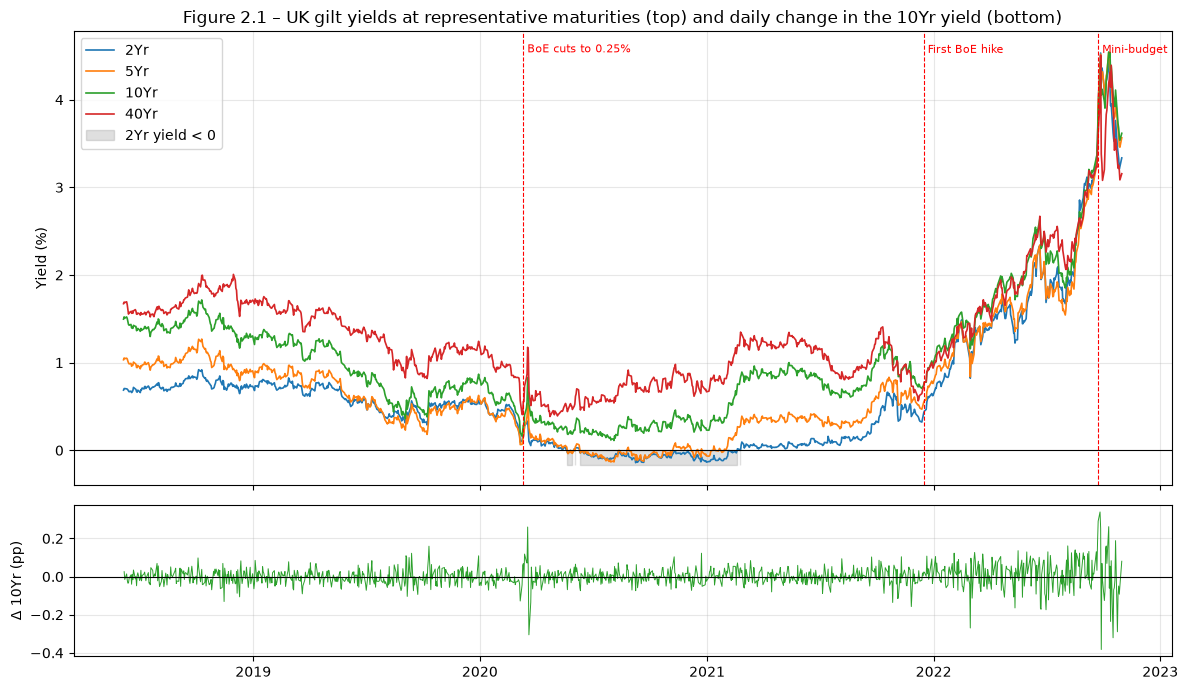

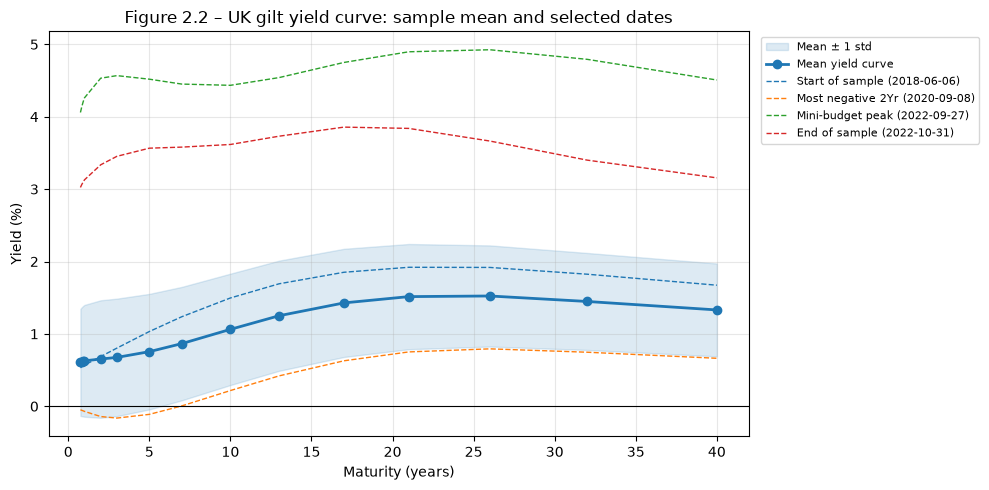

Mean curve peaks at 26Yr (1.524%); 40Yr mean = 1.331% (-0.193 pp vs peak); 10Yr-2Yr mean slope = 0.410 pp


In [23]:
# ---- 2a. Descriptive statistics and graphs of the UK gilt term structure ----
import matplotlib.dates as mdates

# Maturity of each column in years (used as the x-axis of the yield curve)
mat_years = pd.Series([9/12, 10/12, 11/12, 1, 2, 3, 5, 7, 10, 13, 17, 21, 26, 32, 40],
                      index=gilts.columns)
d_gilts = gilts.diff().dropna()                              # daily yield changes (percentage points)

# --- Table 2.1: one row per maturity ---
# Levels: moments + first-order autocorrelation (persistence, close to 1 hints at a unit root).
# Changes: volatility and autocorrelation of the daily changes (should look close to white noise if I(1)).
desc = pd.DataFrame({
    "Mean":          gilts.mean(),
    "Std":           gilts.std(),
    "Min":           gilts.min(),
    "Median":        gilts.median(),
    "Max":           gilts.max(),
    "Skew":          gilts.skew(),
    "Ex. kurt":      gilts.kurt(),
    "AC(1) level":   gilts.apply(lambda c: c.autocorr(1)),
    "Std Δy":        d_gilts.std(),
    "AC(1) Δy":      d_gilts.apply(lambda c: c.autocorr(1)),
    "% days < 0":    100 * (gilts < 0).mean(),
})
desc_notes = (
    f"Notes: Daily UK gilt yields in percent from {gilts.index[0]:%B %-d, %Y} to {gilts.index[-1]:%B %-d, %Y} "
    f"({len(gilts)} trading days). Ex. kurt is excess kurtosis (normal = 0). AC(1) level is the first-order "
    "autocorrelation of the yield level; Std Δy and AC(1) Δy are the standard deviation (percentage points) and "
    "first-order autocorrelation of daily yield changes. % days < 0 is the share of days with a negative yield."
)
save_table(desc, "Table 2.1 - Descriptive statistics of daily UK gilt yields", notes=desc_notes,
           col_formats={"AC(1) level": "num3", "Std Δy": "num3", "AC(1) Δy": "num3", "% days < 0": "num"},
           default="num", width=12, label_width=0.6)

# --- Table 2.2: negative-yield episode, only maturities that ever went below zero ---
neg = gilts < 0
neg_cols = neg.columns[neg.any()]
neg_tab = pd.DataFrame({
    "First day < 0":  [gilts.index[neg[c]].min().strftime("%Y-%m-%d") for c in neg_cols],
    "Last day < 0":   [gilts.index[neg[c]].max().strftime("%Y-%m-%d") for c in neg_cols],
    "Days < 0":       neg[neg_cols].sum().astype(float).values,
    "Min yield (%)":  gilts[neg_cols].min().values,
    "Date of min":    [gilts[c].idxmin().strftime("%Y-%m-%d") for c in neg_cols],
}, index=neg_cols)
neg_notes = ("Notes: Only maturities with at least one negative daily yield are shown. "
             "Days < 0 counts trading days with a negative yield (not necessarily consecutive).")
save_table(neg_tab, "Table 2.2 - Negative-yield episode by maturity", notes=neg_notes,
           col_formats={"Days < 0": "int", "Min yield (%)": "num3"}, width=8.5, label_width=0.6)

# --- Figure 2.1: representative maturities (levels) + daily changes of the 10Yr ---
events = {"2020-03-11": "BoE cuts to 0.25%",          # COVID emergency cuts (0.75% -> 0.25% -> 0.10% on 19 Mar)
          "2021-12-16": "First BoE hike",             # Bank Rate 0.10% -> 0.25%
          "2022-09-23": "Mini-budget"}                # Truss/Kwarteng fiscal event -> gilt sell-off / LDI crisis

fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(12, 7), sharex=True, gridspec_kw={"height_ratios": [3, 1]})
for col in ["2Yr", "5Yr", "10Yr", "40Yr"]:
    ax1.plot(gilts.index, gilts[col], lw=1.2, label=col)
ax1.axhline(0, color="black", lw=0.8)
ax1.fill_between(gilts.index, gilts.min().min(), 0, where=neg["2Yr"],      # shade days with a negative 2Yr yield
                 color="grey", alpha=0.25, label="2Yr yield < 0")
for date, label in events.items():
    ax1.axvline(pd.Timestamp(date), color="red", ls="--", lw=0.8)
    ax1.text(pd.Timestamp(date), ax1.get_ylim()[1] * 0.97, " " + label, color="red", fontsize=8, va="top")
ax1.set_ylabel("Yield (%)")
ax1.set_title("Figure 2.1 – UK gilt yields at representative maturities (top) and daily change in the 10Yr yield (bottom)")
ax1.legend(loc="upper left")
ax1.grid(alpha=0.3)

ax2.plot(d_gilts.index, d_gilts["10Yr"], lw=0.7, color="tab:green")
ax2.axhline(0, color="black", lw=0.8)
ax2.set_ylabel("Δ 10Yr (pp)")
ax2.xaxis.set_major_locator(mdates.YearLocator())
ax2.xaxis.set_major_formatter(mdates.DateFormatter("%Y"))
ax2.grid(alpha=0.3)
plt.tight_layout()
save_output(fig, "Figure 2.1 – UK gilt yields at representative maturities")
plt.show()

# --- Figure 2.2: mean yield curve (+/- 1 std across days) and curves on a few key dates ---
snap_dates = {"Start of sample": gilts.index[0],
              "Most negative 2Yr": gilts["2Yr"].idxmin(),
              "Mini-budget peak": pd.Timestamp("2022-09-27"),
              "End of sample": gilts.index[-1]}

fig, ax = plt.subplots(figsize=(10, 5))
ax.fill_between(mat_years, gilts.mean() - gilts.std(), gilts.mean() + gilts.std(),
                color="tab:blue", alpha=0.15, label="Mean ± 1 std")
ax.plot(mat_years, gilts.mean(), "o-", color="tab:blue", lw=2, label="Mean yield curve")
for label, date in snap_dates.items():
    ax.plot(mat_years, gilts.loc[date], lw=1, ls="--", label=f"{label} ({date:%Y-%m-%d})")
ax.axhline(0, color="black", lw=0.8)
ax.set_xlabel("Maturity (years)")
ax.set_ylabel("Yield (%)")
ax.set_title("Figure 2.2 – UK gilt yield curve: sample mean and selected dates")
ax.legend(fontsize=8, loc="upper left", bbox_to_anchor=(1.01, 1))   # legend outside the plot area
ax.grid(alpha=0.3)
plt.tight_layout()
save_output(fig, "Figure 2.2 – UK gilt yield curve mean and selected dates")
plt.show()

# Where the mean curve peaks (hump) and how much it falls back at 40Yr
peak = gilts.mean().idxmax()
print(f"Mean curve peaks at {peak} ({gilts.mean()[peak]:.3f}%); "
      f"40Yr mean = {gilts.mean()['40Yr']:.3f}% ({gilts.mean()['40Yr'] - gilts.mean()[peak]:+.3f} pp vs peak); "
      f"10Yr-2Yr mean slope = {(gilts['10Yr'] - gilts['2Yr']).mean():.3f} pp")

## 2b. `Q2_ADF()` [10 pts]
Function taking a Series `s` and integer `p`; returns (i) ADF t-stat, constant; (ii) ADF t-stat, constant + trend; (iii) δ = T·β̂, constant; (iv) δ, constant + trend. Apply to 2Yr and 10Yr with p = 5.

In [24]:
# Creating the function and will apply it to the 2Yr and 10Yr yield series with lag p = 5
def Q2_ADF(s, p):
    """Augmented Dickey-Fuller statistics with p lagged differences.

    Estimates by OLS the two ADF regressions
        constant:          Δy_t = α         + β y_{t-1} + Σ_{i=1..p} φ_i Δy_{t-i} + v_t
        constant + trend:  Δy_t = α + γ t   + β y_{t-1} + Σ_{i=1..p} φ_i Δy_{t-i} + v_t
    and tests H0: β = 0 (unit root) against HA: β < 0 (stationary / trend-stationary).

    Parameters
    ----------
    s : pd.Series or array-like
        The series y_1, ..., y_n (oldest first).
    p : int
        Number of lagged differences Δy_{t-1}, ..., Δy_{t-p}.

    Returns
    -------
    pd.Series
        In this order: (i) t-stat, constant; (ii) t-stat, constant + trend;
        (iii) δ = T·β̂, constant; (iv) δ = T·β̂, constant + trend.
        T = n - p - 1 is the number of observations used in the regression
        (one lost to the first difference, p lost to the lagged differences).
    """
    y = np.asarray(s, dtype=float)
    dy = np.diff(y)                                     # Δy_2, ..., Δy_n  (length n - 1)
    n_dy = len(dy)
    T = n_dy - p                                        # usable rows: first p differences are only used as lags

    # Regression variables, all aligned on the same dates t = p + 2, ..., n
    lhs = dy[p:]                                        # Δy_t
    y_lag = y[p:-1]                                     # y_{t-1}
    dy_lags = [dy[p - i:n_dy - i] for i in range(1, p + 1)]   # Δy_{t-1}, ..., Δy_{t-p}
    const = np.ones(T)
    trend = np.arange(1, T + 1)                         # deterministic time trend t

    stats_out = {}
    
    for spec, deterministic in {"const": [const], "trend": [const, trend]}.items():
        X = np.column_stack(deterministic + [y_lag] + dy_lags)
        coef = np.linalg.lstsq(X, lhs, rcond=None)[0]   # OLS coefficients
        resid = lhs - X @ coef
        sigma2 = resid @ resid / (T - X.shape[1])       # residual variance (degrees-of-freedom corrected)
        k = len(deterministic)                          # position of β: right after the deterministic terms
        se_beta = np.sqrt(sigma2 * np.linalg.inv(X.T @ X)[k, k])
        stats_out[spec] = (coef[k] / se_beta, T * coef[k])   # (ADF t-statistic, normalized bias δ)

    return pd.Series([stats_out["const"][0], stats_out["trend"][0],
                      stats_out["const"][1], stats_out["trend"][1]],
                     index=["t-stat (constant)", "t-stat (trend)", "δ (constant)", "δ (trend)"])


# ---- Apply to the 2Yr and 10Yr yields, p = 5 ----
p = 5
maturities_2b = ["2Yr", "10Yr"]
adf_full = pd.DataFrame({m: Q2_ADF(gilts[m], p) for m in maturities_2b}).T

# Robustness: same test on the sample before the first BoE hike (16 Dec 2021), i.e. ending 15 Dec 2021,
# to see whether the 2022 surge in yields drives the result
pre_hike_end = "2021-12-15"
adf_pre = pd.DataFrame({m: Q2_ADF(gilts[m].loc[:pre_hike_end], p) for m in maturities_2b}).T

# Cross-check: our t-statistics must equal statsmodels' adfuller (same lags, no automatic lag selection)
for m in maturities_2b:
    for reg, col in [("c", "t-stat (constant)"), ("ct", "t-stat (trend)")]:
        t_sm, pval_sm = adfuller(gilts[m], maxlag=p, regression=reg, autolag=None, result_object=False)[:2]
        print(f"{m:>4} {col:<18} ours = {adf_full.loc[m, col]:7.4f}   statsmodels = {t_sm:7.4f}   "
              f"MacKinnon p-value = {pval_sm:.3f}")

# Asymptotic Dickey-Fuller critical values (left tail) for comparison
# t-stat: Hamilton (1994) Table B.6, cases 2 (constant) and 4 (trend); δ: Table B.5, same cases, T = ∞
crit_asym = pd.DataFrame({"t-stat (constant)": [-2.57, -2.86, -3.43],
                          "t-stat (trend)":    [-3.12, -3.41, -3.96],
                          "δ (constant)":      [-11.3, -14.1, -20.7],
                          "δ (trend)":         [-18.3, -21.8, -29.5]},
                         index=["10%", "5%", "1%"])

n_full = len(gilts) - p - 1
n_pre = len(gilts.loc[:pre_hike_end]) - p - 1
notes_2b = (
    f"Notes: ADF regressions of the daily yield change on a constant (and a linear trend), the lagged yield level "
    f"and p = {p} lagged changes, estimated by OLS. t-stat = estimated β / its standard error; δ = T × estimated β, "
    f"where T is the number of "
    f"observations in the regression (T = {n_full:,} for the full sample {gilts.index[0]:%B %-d, %Y} to "
    f"{gilts.index[-1]:%B %-d, %Y}; T = {n_pre:,} for the sample ending December 15, 2021, the day before the "
    "first Bank of England rate increase). H0: unit root (β = 0); HA: stationary or trend-stationary (β < 0); the test is "
    "one-sided, so the null is rejected only when the statistic is below the critical value. Panel C: asymptotic "
    "Dickey-Fuller critical values from Hamilton (1994), Tables B.5 and B.6 (cases 2 and 4)."
)
save_table({"Panel A: Full sample": adf_full,
            "Panel B: Before the first BoE hike (ends December 15, 2021)": adf_pre,
            "Panel C: Asymptotic Dickey-Fuller critical values": crit_asym},
           "Table 2.3 - ADF tests on the 2Yr and 10Yr UK gilt yields (p = 5)",
           notes=notes_2b, default="num", width=9, label_width=2.6)

 2Yr t-stat (constant)  ours =  1.0007   statsmodels =  1.0007   MacKinnon p-value = 0.994
 2Yr t-stat (trend)     ours =  0.1661   statsmodels =  0.1661   MacKinnon p-value = 0.996
10Yr t-stat (constant)  ours =  0.9300   statsmodels =  0.9300   MacKinnon p-value = 0.993
10Yr t-stat (trend)     ours =  0.1085   statsmodels =  0.1085   MacKinnon p-value = 0.995
Table 2.3 - ADF tests on the 2Yr and 10Yr UK gilt yields (p = 5)
Panel A: Full sample


,t-stat (constant),t-stat (trend),δ (constant),δ (trend)
2Yr,1.00,0.17,2.20,0.39
10Yr,0.93,0.11,2.31,0.28


Panel B: Before the first BoE hike (ends December 15, 2021)


,t-stat (constant),t-stat (trend),δ (constant),δ (trend)
2Yr,-1.39,-1.02,-3.66,-4.10
10Yr,-1.84,-1.56,-5.42,-5.54


Panel C: Asymptotic Dickey-Fuller critical values


,t-stat (constant),t-stat (trend),δ (constant),δ (trend)
10%,-2.57,-3.12,-11.30,-18.30
5%,-2.86,-3.41,-14.10,-21.80
1%,-3.43,-3.96,-20.70,-29.50


## 2c. `Q2_CVSim()` [10 pts]
Function taking a Series `s` and integers `N`, `T`, `p`; returns a 3×4 DataFrame of 90/95/99% critical values for the four statistics, from N bootstrapped random walks (increments drawn from Δs). Apply to 10Yr with p = 5, T = 400, N = 500.

Δ10Yr: mean = 0.0019 pp/day (t = 1.15), std = 0.0554 pp, excess kurtosis = 7.92; drift over T = 400 days = 0.76 pp vs. random-walk std = 1.11 pp
Table 2.4 - Bootstrap ADF critical values from 10Yr gilt increments (p = 5, T = 400)
Panel A: Bootstrap, 10Yr gilt increments (N = 500)


,t-stat (constant),t-stat (trend),δ (constant),δ (trend)
90%,-2.55,-3.12,-10.54,-19.05
95%,-2.94,-3.44,-14.81,-22.15
99%,-3.51,-4.06,-23.63,-26.66


Panel B: Bootstrap, 10Yr gilt increments (N = 10,000)


,t-stat (constant),t-stat (trend),δ (constant),δ (trend)
90%,-2.49,-3.12,-10.57,-18.72
95%,-2.79,-3.41,-13.09,-22.15
99%,-3.39,-4.01,-19.59,-30.51


Panel C: MacKinnon (2010) finite-sample, T = 394


,t-stat (constant),t-stat (trend),δ (constant),δ (trend)
90%,-2.57,-3.13,–,–
95%,-2.87,-3.42,–,–
99%,-3.45,-3.98,–,–


Panel D: Asymptotic Dickey-Fuller


,t-stat (constant),t-stat (trend),δ (constant),δ (trend)
90%,-2.57,-3.12,-11.30,-18.30
95%,-2.86,-3.41,-14.10,-21.80
99%,-3.43,-3.96,-20.70,-29.50


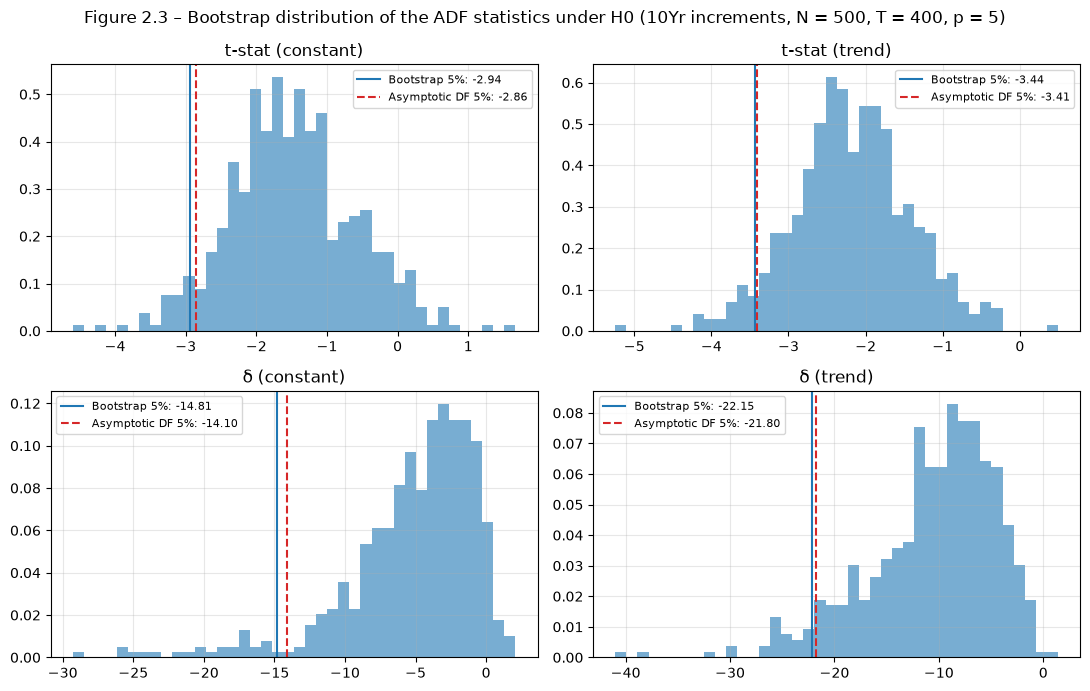

In [25]:
from statsmodels.tsa.adfvalues import mackinnoncrit      # finite-sample Dickey-Fuller critical values (MacKinnon, 2010)

def Q2_CVSim(s, N, T, p, bg=None, return_sims=False):
    """Bootstrap critical values for the four ADF statistics of Q2_ADF().

    (i)   Simulates N random walks of length T. Each increment is drawn uniformly at random,
          with replacement, from the observed changes Δs. The increments are NOT demeaned, so any
          drift in Δs is kept in the simulated random walks.
    (ii)  Runs Q2_ADF(., p) on each simulated random walk.
    (iii) Takes the left-tail percentiles of the N simulated statistics: the 90%, 95% and 99%
          critical values are the 10th, 5th and 1st percentiles (the ADF test rejects for very
          negative values).

    Parameters
    ----------
    s : pd.Series or array-like
        Observed series; its first differences are the pool of increments.
    N : int
        Number of simulated random walks.
    T : int
        Length of each simulated random walk.
    p : int
        Number of lagged differences in the ADF regressions.
    bg : np.random.BitGenerator, optional
        Random number source (default: PCG64(42), so results are reproducible).
    return_sims : bool
        If True, also return the N x 4 simulated statistics (used for Figure 2.3).

    Returns
    -------
    pd.DataFrame
        3 x 4: rows "90%", "95%", "99%"; columns are the four statistics of Q2_ADF(), in the same order.
        (If return_sims is True: a tuple (critical values, simulated statistics).)
    """
    rng = np.random.Generator(bg if bg is not None else np.random.PCG64(42))
    s = np.asarray(s, dtype=float)
    ds = np.diff(s)                                              # pool of observed increments Δs

    # All N random walks at once: N x T matrix of bootstrapped increments, cumulated along each row.
    # Starting value = first observation of s (irrelevant for the statistics, since both ADF
    # regressions include a constant).
    increments = rng.choice(ds, size=(N, T), replace=True)
    walks = s[0] + np.cumsum(increments, axis=1)

    sim_stats = pd.DataFrame([Q2_ADF(walk, p) for walk in walks])   # N x 4 simulated statistics under H0

    crit = sim_stats.quantile([0.10, 0.05, 0.01])                # left tail
    crit.index = ["90%", "95%", "99%"]
    return (crit, sim_stats) if return_sims else crit


# ---- Apply to the 10Yr yield: p = 5, T = 400, N = 500 ----
p, T_sim, N_sim = 5, 400, 500
cv_10y, sims_10y = Q2_CVSim(gilts["10Yr"], N_sim, T_sim, p, return_sims=True)

# Robustness: same bootstrap with N = 10,000 to see how much of the result is Monte Carlo noise
# (with N = 500, the 1% critical value rests on only 5 simulated values in the tail)
N_big = 10_000
cv_10y_big = Q2_CVSim(gilts["10Yr"], N_big, T_sim, p)

# Textbook comparison 1: MacKinnon (2010) finite-sample critical values for the t-statistic,
# for the same regression sample size (T - p - 1 observations); no such table for δ
T_reg = T_sim - p - 1
cv_mackinnon = pd.DataFrame({
    "t-stat (constant)": mackinnoncrit(N=1, regression="c", nobs=T_reg)[::-1],   # returned as 1%, 5%, 10%
    "t-stat (trend)":    mackinnoncrit(N=1, regression="ct", nobs=T_reg)[::-1],
    "δ (constant)":      np.nan,
    "δ (trend)":         np.nan}, index=["90%", "95%", "99%"])

# Textbook comparison 2: asymptotic Dickey-Fuller values (crit_asym from 2b), relabelled 90/95/99%
cv_asym = crit_asym.set_axis(["90%", "95%", "99%"])

# Properties of the increments the bootstrap draws from (drift, volatility, fat tails)
d10 = gilts["10Yr"].diff().dropna()
print(f"Δ10Yr: mean = {d10.mean():.4f} pp/day (t = {d10.mean() / d10.std() * np.sqrt(len(d10)):.2f}), "
      f"std = {d10.std():.4f} pp, excess kurtosis = {d10.kurt():.2f}; "
      f"drift over T = {T_sim} days = {T_sim * d10.mean():.2f} pp vs. random-walk std = {d10.std() * np.sqrt(T_sim):.2f} pp")

notes_2c = (
    f"Notes: Panels A and B: N simulated random walks of length T = {T_sim}, with increments drawn uniformly with "
    f"replacement from the {len(d10):,} observed daily changes of the 10Yr UK gilt yield (not demeaned). Q2_ADF() "
    f"with p = {p} is run on each walk; the 90%, 95% and 99% critical values are the 10th, 5th and 1st percentiles "
    f"of the simulated statistics. Panel A is the specification asked for (N = {N_sim}); Panel B repeats it with "
    f"N = {N_big:,} to measure Monte Carlo noise. Panel C: MacKinnon (2010) finite-sample critical values for "
    f"{T_reg} regression observations (t-statistic only). Panel D: asymptotic Dickey-Fuller critical values, "
    "Hamilton (1994), Tables B.5 and B.6 (cases 2 and 4). Reject the unit root when the statistic is below the value."
)
save_table({f"Panel A: Bootstrap, 10Yr gilt increments (N = {N_sim})": cv_10y,
            f"Panel B: Bootstrap, 10Yr gilt increments (N = {N_big:,})": cv_10y_big,
            f"Panel C: MacKinnon (2010) finite-sample, T = {T_reg}": cv_mackinnon,
            "Panel D: Asymptotic Dickey-Fuller": cv_asym},
           f"Table 2.4 - Bootstrap ADF critical values from 10Yr gilt increments (p = {p}, T = {T_sim})",
           notes=notes_2c, default="num", width=9, label_width=2.9)

# ---- Figure 2.3: simulated distributions of the four statistics under H0 (N = 500) ----
fig, axes = plt.subplots(2, 2, figsize=(11, 7))
for ax, col in zip(axes.ravel(), sims_10y.columns):
    ax.hist(sims_10y[col], bins=40, color="tab:blue", alpha=0.6, density=True)
    ax.axvline(cv_10y.loc["95%", col], color="tab:blue", lw=1.5, label=f"Bootstrap 5%: {cv_10y.loc['95%', col]:.2f}")
    ax.axvline(cv_asym.loc["95%", col], color="tab:red", ls="--", lw=1.5, label=f"Asymptotic DF 5%: {cv_asym.loc['95%', col]:.2f}")
    ax.set_title(col)
    ax.legend(fontsize=8)
    ax.grid(alpha=0.3)
fig.suptitle(f"Figure 2.3 – Bootstrap distribution of the ADF statistics under H0 (10Yr increments, N = {N_sim}, T = {T_sim}, p = {p})")
plt.tight_layout()
save_output(fig, "Figure 2.3 – Bootstrap distribution of the ADF statistics under H0")
plt.show()

## 2d. Bootstrap critical values for the log S&P 500 [10 pts]
`Q2_CVSim()` on the last 400 obs of the log S&P 500 with p = 3, T = 400, N = 500. Compare with 2c, then apply `Q2_ADF()` (last 400 obs, p = 3).

## 2e. `Q2_RollingADF()` [10 pts]
Function taking a Series `s` and integers `p`, `N < len(s)`; runs `Q2_ADF()` on every rolling window of N obs. Returns a 3×4 DataFrame: most negative value, window start date, window end date. Apply to 10Yr with p = 5, N = 250.

## 2f. Rolling ADF on the log S&P 500 [5 pts]
`Q2_RollingADF()` on the last 1,500 obs of the log S&P 500 with p = 3, N = 250.

# Problem 3 – Practice for the Final Exam [10 pts]
True / False / Cannot be determined, with full justification. Answered in the write-up (no code needed).
1. Mean forecast error = 0 t-test to evaluate calibration.
2. 10-fold CV to select AR lag order on a monthly macro series.
3. AR(1) with φ̂1 = 0.97 (s.e. 0.015) ⇒ stationary.
4. Reject KPSS + fail to reject Phillips–Perron ⇒ I(1).